In [1]:
import pandas as pd
spectraverse_spec_df = pd.read_pickle('../../data/proc/spectraverse/spec_df.pkl')
spectraverse_spec_df

In [2]:
#spectraverse_spec_df['ace'] = spectraverse_spec_df.apply(lambda x: round(x['prec_mz'] * x['nce'] / 500, 0), axis=1)


In [3]:
# Number of spectra with non-null ACE value
num_spec_with_ace = spectraverse_spec_df['ace'].notnull().sum()
print(f"Number of spectra with ACE: {num_spec_with_ace:,}")

# Number of unique (mol_id, prec_type) pairs with at least one spectrum with ACE
spec_with_ace = spectraverse_spec_df[spectraverse_spec_df['ace'].notnull()]
unique_mol_adduct_with_ace = spec_with_ace.groupby(['mol_id', 'prec_type']).ngroups
print(f"Number of unique (mol_id, adduct type) pairs with ACE: {unique_mol_adduct_with_ace:,}")

Number of spectra with ACE: 273,012
Number of unique (mol_id, adduct type) pairs with ACE: 44,347


In [4]:
# Number of unique (mol_id, prec_type) pairs with ACE, grouped by adduct types
ace_pairs_by_adduct = spec_with_ace.groupby('prec_type')['mol_id'].nunique().sort_values(ascending=False)

print("Number of unique (mol_id, adduct type) pairs with ACE by adduct type:")
print("-" * 60)
for adduct, count in ace_pairs_by_adduct.items():
    print(f"{adduct:15s}: {count:,}")

print(f"\nTotal unique (mol_id, adduct type) pairs with ACE: {ace_pairs_by_adduct.sum():,}")

Number of unique (mol_id, adduct type) pairs with ACE by adduct type:
------------------------------------------------------------
[M+H]+         : 18,636
[M-H]-         : 12,687
[M+Na]+        : 3,757
[M+HCOOH-H]-   : 3,205
[M+NH4]+       : 2,153
[M+Cl]-        : 1,580
[M+K]+         : 1,554
[M+CH3COOH-H]- : 452
[M]+           : 323

Total unique (mol_id, adduct type) pairs with ACE: 44,347


In [5]:
# Group by prec_type (adducts) and count the number of spectra in each group
adduct_counts = spectraverse_spec_df['prec_type'].value_counts().sort_values(ascending=False)
# Display the results
print(f"Number of unique adduct types: {len(adduct_counts)}")
print("\nTop adduct types:\n")
print(adduct_counts)

Number of unique adduct types: 9

Top adduct types:

prec_type
[M+H]+            233103
[M-H]-            107867
[M+Na]+            69475
[M+NH4]+           34889
[M+HCOOH-H]-       16136
[M+K]+              9508
[M+CH3COOH-H]-      8456
[M+Cl]-             5958
[M]+                3405
Name: count, dtype: int64


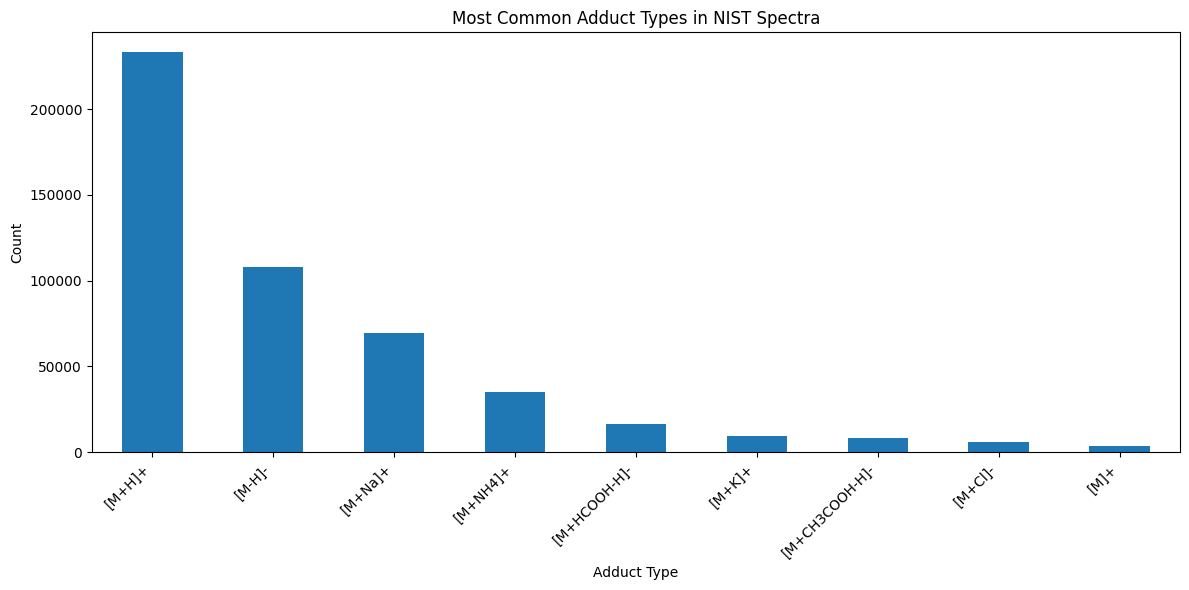

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
adduct_counts.head(50).plot(kind='bar')
plt.title('Most Common Adduct Types in NIST Spectra')
plt.ylabel('Count')
plt.xlabel('Adduct Type')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [7]:
spectraverse_mol_df = pd.read_pickle('../../data/proc/spectraverse/mol_df.pkl')
spectraverse_mol_df.head()

In [8]:
spectraverse_mol_df.iloc[0]

smiles                               Brc1[nH]c2c(Br)ccc(Br)c2c1Br
mol_id                                                          0
mol              <rdkit.Chem.rdchem.Mol object at 0x7fbf85fd61b0>
inchikey_s                                         WCHRWOPQXYKKJZ
scaffold                                         c1ccc2[nH]ccc2c1
formula                                                  C8H3Br4N
inchi           InChI=1S/C8H3Br4N/c9-3-1-2-4(10)7-5(3)6(11)8(1...
mw                                                        432.735
exact_mw                                               428.699897
num_atoms                                                      13
num_bonds                                                      14
charge                                                          0
single_mol                                                   True
num_radicals                                                    0
Name: 0, dtype: object

In [9]:
spectraverse_df = spectraverse_spec_df.merge(spectraverse_mol_df, on='mol_id', how='left')

spectraverse_df.head()

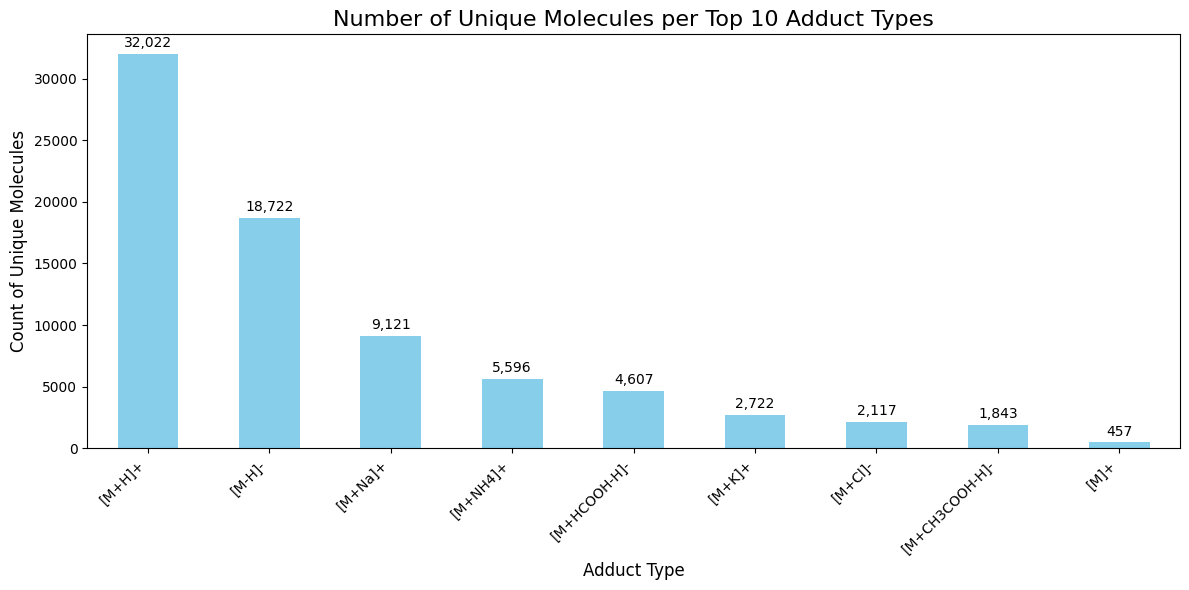

Number of unique molecules per adduct type:
prec_type
[M+H]+            32022
[M-H]-            18722
[M+Na]+            9121
[M+NH4]+           5596
[M+HCOOH-H]-       4607
[M+K]+             2722
[M+Cl]-            2117
[M+CH3COOH-H]-     1843
[M]+                457
Name: mol_id, dtype: int64


In [10]:
# Calculate the number of unique molecules per each adduct type
unique_mols_per_adduct = spectraverse_df.groupby('prec_type')['mol_id'].nunique().sort_values(ascending=False)

# Get the top 10 adduct types by number of unique molecules
top_10_adducts_by_mols = unique_mols_per_adduct.head(10)

# Create a bar plot
plt.figure(figsize=(12, 6))
top_10_adducts_by_mols.plot(kind='bar', color='skyblue')

# Add labels and title
plt.title('Number of Unique Molecules per Top 10 Adduct Types', fontsize=16)
plt.xlabel('Adduct Type', fontsize=12)
plt.ylabel('Count of Unique Molecules', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Add value labels on top of each bar
for i, v in enumerate(top_10_adducts_by_mols):
    plt.text(i, v + 0.01*max(top_10_adducts_by_mols), f"{v:,}", 
             ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

# Print the counts as well
print("Number of unique molecules per adduct type:")
print(top_10_adducts_by_mols)

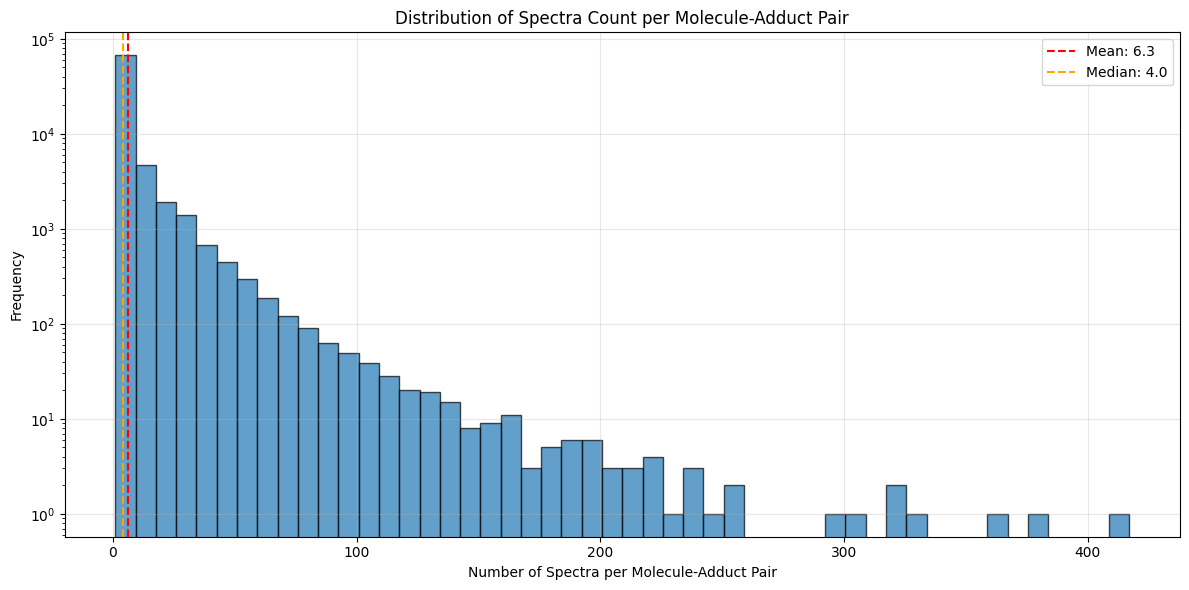

Total molecule-adduct pairs: 77,207
Mean spectra per pair: 6.33
Median spectra per pair: 4.00
Max spectra per pair: 417
Min spectra per pair: 1


In [11]:
# Calculate the number of spectra per molecule-adduct pair
spectra_per_mol_adduct = spectraverse_df.groupby(['mol_id', 'prec_type']).size()

# Create histogram
plt.figure(figsize=(12, 6))
plt.hist(spectra_per_mol_adduct, bins=50, edgecolor='black', alpha=0.7)
plt.xlabel('Number of Spectra per Molecule-Adduct Pair')
plt.ylabel('Frequency')
plt.title('Distribution of Spectra Count per Molecule-Adduct Pair')
plt.yscale('log')  # Use log scale for better visualization
plt.grid(True, alpha=0.3)

# Add some statistics
mean_spectra = spectra_per_mol_adduct.mean()
median_spectra = spectra_per_mol_adduct.median()
plt.axvline(mean_spectra, color='red', linestyle='--', label=f'Mean: {mean_spectra:.1f}')
plt.axvline(median_spectra, color='orange', linestyle='--', label=f'Median: {median_spectra:.1f}')
plt.legend()

plt.tight_layout()
plt.show()

# Print summary statistics
print(f"Total molecule-adduct pairs: {len(spectra_per_mol_adduct):,}")
print(f"Mean spectra per pair: {mean_spectra:.2f}")
print(f"Median spectra per pair: {median_spectra:.2f}")
print(f"Max spectra per pair: {spectra_per_mol_adduct.max()}")
print(f"Min spectra per pair: {spectra_per_mol_adduct.min()}")

In [ ]:
import ms_entropy as me
import numpy as np
from tqdm.notebook import tqdm

print("Calculating spectral entropy...")
#peaks_query = np.array(spectraverse_spec_df.iloc[0]['peaks'])
#me.calculate_spectral_entropy(peaks_query, clean_spectrum = True, min_ms2_difference_in_da = 0.05)

tqdm.pandas(desc="Processing")
spectraverse_spec_df['ms_entropy'] = spectraverse_spec_df['peaks'].progress_apply(
    lambda peaks: me.calculate_spectral_entropy(
        np.array(peaks), clean_spectrum=True, min_ms2_difference_in_da=0.05
    )
)

Calculating spectral entropy...


Processing:   0%|          | 0/488797 [00:00<?, ?it/s]

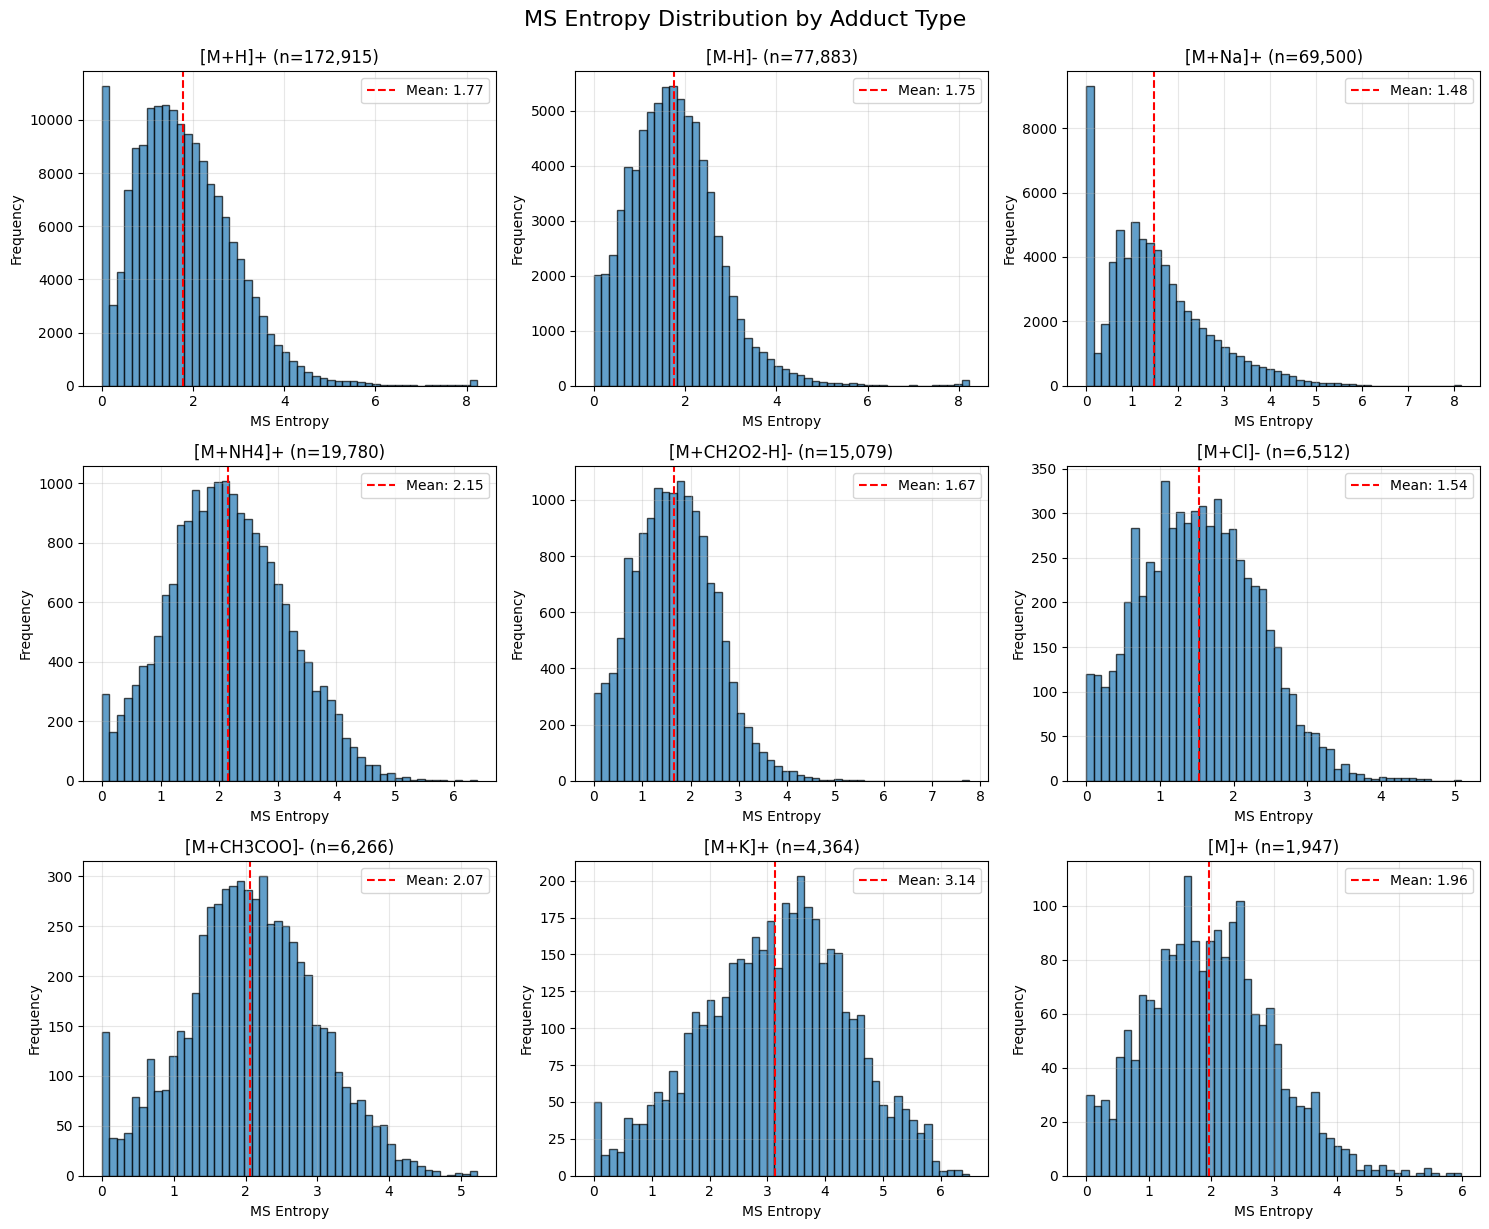

MS Entropy Statistics by Adduct Type:
--------------------------------------------------
[M+H]+      : Mean=1.769, Std=1.104, Median=1.657, Count=172,915
[M-H]-      : Mean=1.749, Std=0.987, Median=1.682, Count=77,883
[M+Na]+     : Mean=1.479, Std=1.110, Median=1.311, Count=69,500
[M+NH4]+    : Mean=2.147, Std=0.993, Median=2.105, Count=19,780
[M+CH2O2-H]-: Mean=1.667, Std=0.836, Median=1.641, Count=15,079
[M+Cl]-     : Mean=1.537, Std=0.786, Median=1.513, Count=6,512
[M+CH3COO]- : Mean=2.065, Std=0.913, Median=2.057, Count=6,266
[M+K]+      : Mean=3.135, Std=1.257, Median=3.225, Count=4,364
[M]+        : Mean=1.962, Std=0.980, Median=1.929, Count=1,947


In [ ]:
# Create subplots for entropy distribution by adduct type
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

top_adducts = ['[M+H]+', '[M-H]-', '[M+Na]+', '[M+NH4]+', '[M+CH2O2-H]-', '[M+Cl]-', '[M+CH3COO]-', '[M+K]+', '[M]+']

for i, adduct in enumerate(top_adducts):
    adduct_data = spectraverse_spec_df[spectraverse_spec_df['prec_type'] == adduct]['ms_entropy']
    
    axes[i].hist(adduct_data, bins=50, alpha=0.7, edgecolor='black')
    axes[i].set_title(f'{adduct} (n={len(adduct_data):,})')
    axes[i].set_xlabel('MS Entropy')
    axes[i].set_ylabel('Frequency')
    axes[i].grid(True, alpha=0.3)
    
    # Add mean line
    mean_entropy = adduct_data.mean()
    axes[i].axvline(mean_entropy, color='red', linestyle='--', 
                   label=f'Mean: {mean_entropy:.2f}')
    axes[i].legend()

plt.tight_layout()
plt.suptitle('MS Entropy Distribution by Adduct Type', fontsize=16, y=1.02)
plt.show()

# Print summary statistics
print("MS Entropy Statistics by Adduct Type:")
print("-" * 50)
for adduct in top_adducts:
    adduct_data = spectraverse_spec_df[spectraverse_spec_df['prec_type'] == adduct]['ms_entropy']
    print(f"{adduct:12s}: Mean={adduct_data.mean():.3f}, Std={adduct_data.std():.3f}, "
          f"Median={adduct_data.median():.3f}, Count={len(adduct_data):,}")

In [ ]:
spectraverse_spec_df['num_peaks'] = spectraverse_spec_df['peaks'].apply(lambda x: len(x))

/tmp/ipykernel_3984666/491564942.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


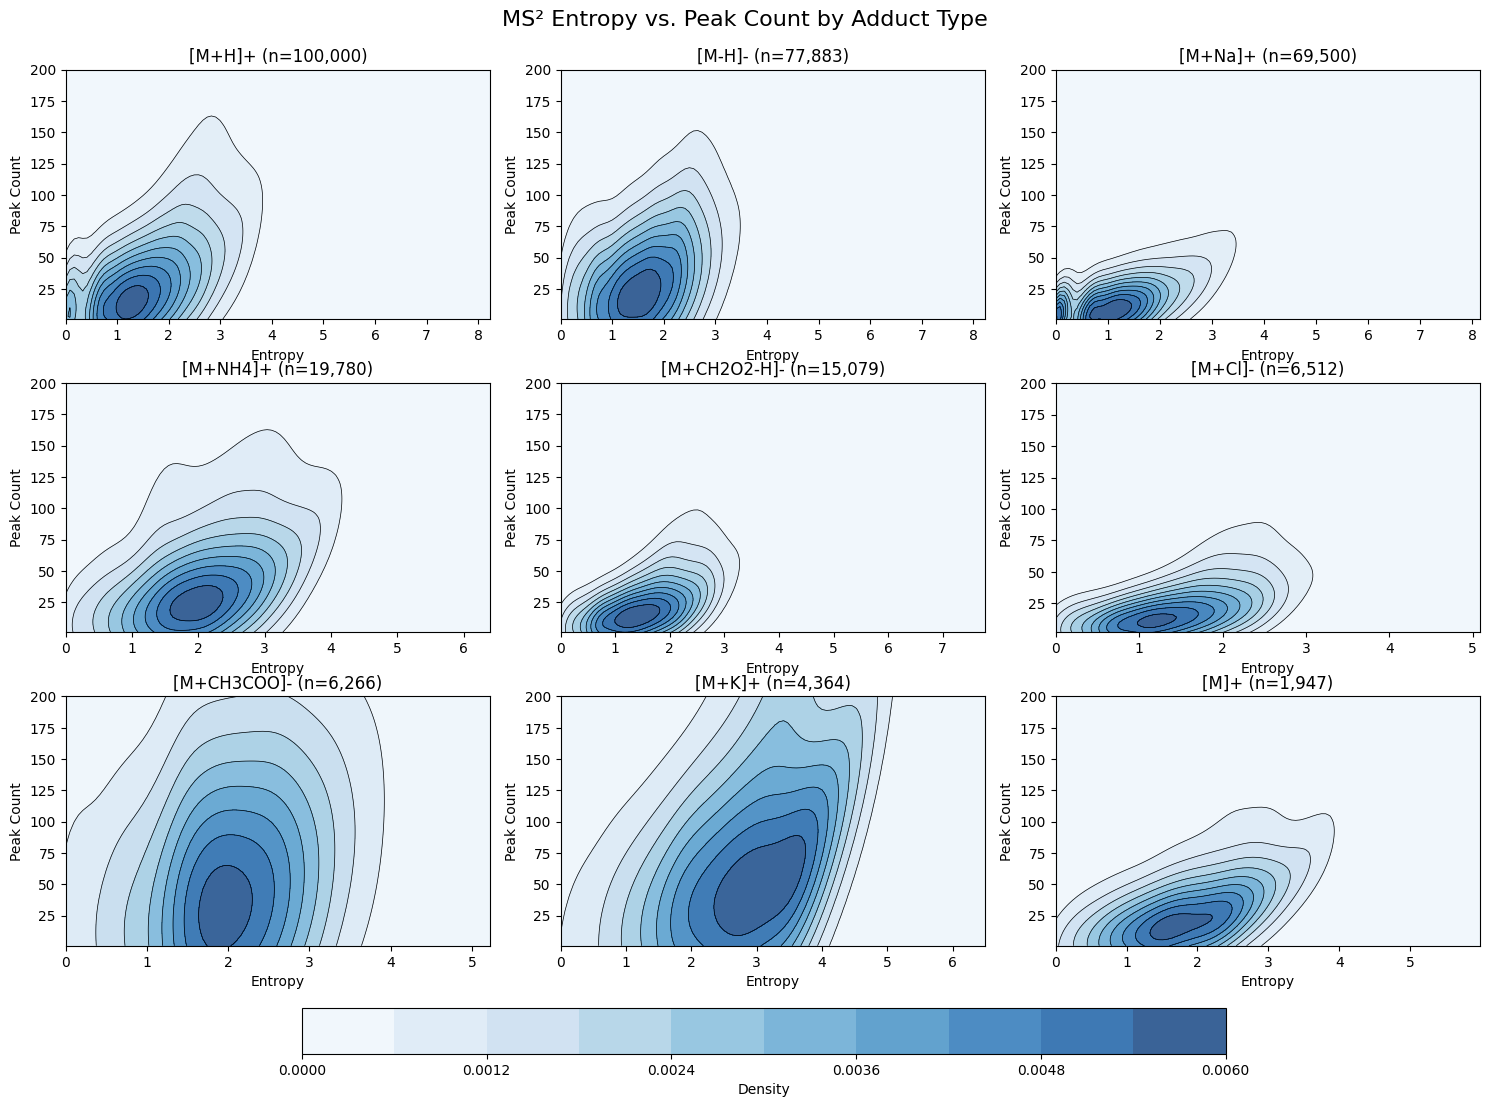

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

top_adducts = ['[M+H]+', '[M-H]-', '[M+Na]+', '[M+NH4]+', '[M+CH2O2-H]-', '[M+Cl]-', '[M+CH3COO]-', '[M+K]+', '[M]+']

contourf_handles = []

for i, adduct in enumerate(top_adducts):
    adduct_data = spectraverse_spec_df[spectraverse_spec_df['prec_type'] == adduct]
    sampled_df = adduct_data.sample(n=min(100_000, len(adduct_data)))
    entropy = sampled_df['ms_entropy'].values
    peak_num = sampled_df['num_peaks'].values

    if len(entropy) < 2:
        axes[i].text(0.5, 0.5, 'Insufficient Data', ha='center')
        axes[i].set_title(f'{adduct} (n={len(sampled_df)})')
        continue

    values = np.vstack([entropy, peak_num])
    kernel = gaussian_kde(values)

    x_min, x_max = entropy.min(), entropy.max()
    y_min, y_max = peak_num.min(), min(peak_num.max(), 200)
    X, Y = np.mgrid[x_min:x_max:100j, y_min:y_max:100j]
    positions = np.vstack([X.ravel(), Y.ravel()])
    Z = np.reshape(kernel(positions).T, X.shape)

    levels = 10
    cf = axes[i].contourf(X, Y, Z, levels=levels, cmap='Blues', alpha=0.8)
    axes[i].contour(X, Y, Z, levels=levels, colors='black', linewidths=0.5)
    axes[i].set_xlabel('Entropy')
    axes[i].set_ylabel('Peak Count')
    axes[i].set_title(f'{adduct} (n={len(sampled_df):,})')
    axes[i].set_ylim(y_min, y_max)
    contourf_handles.append(cf)

# Add a single colorbar for the last contourf plot
cbar = fig.colorbar(contourf_handles[-1], ax=axes, orientation='horizontal', fraction=0.05, pad=0.01)
cbar.set_label('Density')

plt.tight_layout()
plt.subplots_adjust(top=0.93, bottom=0.2)  # Adjust bottom as needed
fig.suptitle('MS² Entropy vs. Peak Count by Adduct Type', fontsize=16)
plt.show()

In [ ]:
nist_spectra_df = pd.read_pickle('../../data/proc/nist20/spec_df.pkl')
nist_spectra_df.head()

In [ ]:
nist_mol_df = pd.read_pickle('../../data/proc/nist20/mol_df.pkl')
nist_mol_df.drop(['mol'], axis=1, inplace=True)
nist_mol_df.head()

In [ ]:
# Left join nist_spectra_df and nist_mol_df on 'mol_id', filter for dset == 'nist20_hr'
nist20_hr_df = nist_spectra_df.merge(nist_mol_df, on='mol_id', how='left')
nist20_hr_df = nist20_hr_df[nist20_hr_df['dset'] == 'nist20_hr']

nist20_hr_df.head()

In [ ]:
# Find inchikey_s in spectraverse_mol_df that are not in nist_mol_df
inchikeys_spectraverse = set(spectraverse_mol_df['inchikey_s'])
inchikeys_nist = set(nist20_hr_df['inchikey_s'])

unique_inchikeys = inchikeys_spectraverse - inchikeys_nist
print(f"Number of inchikey_s in spectraverse_mol_df not in nist_mol_df: {len(unique_inchikeys):,}")

Number of inchikey_s in spectraverse_mol_df not in nist_mol_df: 30,003


In [ ]:
# Get mol_id values for unique_inchikeys from spectraverse_mol_df
unique_mol_ids = spectraverse_mol_df[spectraverse_mol_df['inchikey_s'].isin(unique_inchikeys)]['mol_id'].unique()

# Create a subset of spectraverse_spec_df for these mol_ids
unique_spec_subset = spectraverse_spec_df[spectraverse_spec_df['mol_id'].isin(unique_mol_ids)]

unique_spec_subset.head()

In [ ]:
num_with_ace = unique_spec_subset['ace'].notnull().sum()
print(f"Number of spectra in unique_spec_subset with collision energy (ACE): {num_with_ace:,}")

Number of spectra in unique_spec_subset with collision energy (ACE): 13,408


In [ ]:
# Count number of (mol_id, prec_type) pairs with ACE in unique_spec_subset, grouped by adduct type
spec_with_ace_unique = unique_spec_subset[unique_spec_subset['ace'].notnull()]
adduct_mol_pairs_with_ace = spec_with_ace_unique.groupby('prec_type')['mol_id'].nunique().sort_values(ascending=False)

print("Number of (mol_id, adduct type) pairs with ACE in unique_spec_subset by adduct type:")
print("-" * 60)
for adduct, count in adduct_mol_pairs_with_ace.items():
    print(f"{adduct:15s}: {count:,}")

print(f"\nTotal unique (mol_id, adduct type) pairs with ACE in unique_spec_subset: {adduct_mol_pairs_with_ace.sum():,}")

Number of (mol_id, adduct type) pairs with ACE in unique_spec_subset by adduct type:
------------------------------------------------------------
[M+H]+         : 2,223
[M-H]-         : 1,580
[M+Na]+        : 352
[M+K]+         : 273
[M+CH3COO]-    : 253
[M+NH4]+       : 237
[M]+           : 147
[M+CH2O2-H]-   : 30
[M+Cl]-        : 1

Total unique (mol_id, adduct type) pairs with ACE in unique_spec_subset: 5,096


In [ ]:
nist23_spectra_df = pd.read_pickle('../../data/proc/nist23mona23/spec_df.pkl')
nist23_spectra_df.head()

In [ ]:
nist23_mol_df = pd.read_pickle('../../data/proc/nist23mona23/mol_df.pkl')
nist23_mol_df.drop(['mol'], axis=1, inplace=True)
nist23_mol_df.head()

In [ ]:
# Left join nist_spectra_df and nist_mol_df on 'mol_id', filter for dset == 'nist20_hr'
nist23_hr_df = nist23_spectra_df.merge(nist23_mol_df, on='mol_id', how='left')
nist23_spectra_df = nist23_spectra_df[nist23_spectra_df['dset'].isin(['nist23_hr1', 'nist23_hr2'])]
nist23_spectra_df.shape

nist23_hr_df.head()

In [ ]:
# Find inchikey_s in spectraverse_mol_df that are not in nist_mol_df
inchikeys_spectraverse = set(spectraverse_mol_df['inchikey_s'])
inchikeys_nist23 = set(nist23_hr_df['inchikey_s'])

unique_inchikeys = inchikeys_spectraverse - inchikeys_nist23
print(f"Number of inchikey_s in spectraverse_mol_df not in nist_mol_df: {len(unique_inchikeys):,}")

num_with_ace = unique_spec_subset['ace'].notnull().sum()
print(f"Number of spectra in unique_spec_subset with collision energy (ACE): {num_with_ace:,}")

Number of inchikey_s in spectraverse_mol_df not in nist_mol_df: 24,110
Number of spectra in unique_spec_subset with collision energy (ACE): 13,408


In [ ]:
# Get mol_id values for unique_inchikeys from spectraverse_mol_df
unique_mol_ids = spectraverse_mol_df[spectraverse_mol_df['inchikey_s'].isin(unique_inchikeys)]['mol_id'].unique()

# Create a subset of spectraverse_spec_df for these mol_ids
unique_spec_subset = spectraverse_spec_df[spectraverse_spec_df['mol_id'].isin(unique_mol_ids)]

unique_spec_subset.head()

# Count number of (mol_id, prec_type) pairs with ACE in unique_spec_subset, grouped by adduct type
spec_with_ace_unique = unique_spec_subset[unique_spec_subset['ace'].notnull()]
adduct_mol_pairs_with_ace = spec_with_ace_unique.groupby('prec_type')['mol_id'].nunique().sort_values(ascending=False)

print("Number of (mol_id, adduct type) pairs with ACE in unique_spec_subset by adduct type:")
print("-" * 60)
for adduct, count in adduct_mol_pairs_with_ace.items():
    print(f"{adduct:15s}: {count:,}")

print(f"\nTotal unique (mol_id, adduct type) pairs with ACE in unique_spec_subset: {adduct_mol_pairs_with_ace.sum():,}")

Number of (mol_id, adduct type) pairs with ACE in unique_spec_subset by adduct type:
------------------------------------------------------------
[M+H]+         : 443
[M-H]-         : 222
[M]+           : 65
[M+Na]+        : 38
[M+NH4]+       : 27
[M+K]+         : 24
[M+CH2O2-H]-   : 9

Total unique (mol_id, adduct type) pairs with ACE in unique_spec_subset: 828
